# Feature visualization for pretrained CNNs using gradient ascent

This notebook investigates the generation of class-specific feature visualizations through gradient ascent on three pretrained convolutional neural networks (CNNs). It is organized into seven sections, beginning with an introduction to the two research questions and objectives, followed by environment setup and measures to ensure reproducibility, such as managing dependencies with Conda. Thereafter, the pretrained models (VGG-16, VGG-19, and ResNet-152) are loaded and verified, and the implementation of the gradient ascent algorithm as well as reusabile visualization and evaluation functions will be done. The two research questions are then investigated through separate experiments on cross-model transferability (RQ1) and the effects of optimization and regularization (RQ2). Finally, the results are presented and interpreted, leading into conclusions for the project.

## 1. Introduction and objectives

Convolutional neural networks (CNNs) perform well in image classification, but understanding which features they use for their predictions remains challenging. Gradient-ascent feature visualization can help explore these learned representations by generating images that strongly activate a specific class.

In this project, we will generate class-specific images using three pre-trained CNNs and investigate whether the images generated for each model also strongly activate the target class in the other two. By comparing two similar architectures (VGG-16 and VGG-19) with a more structurally different architecture (ResNet-152), we aim to examine the following research questions:

- **RQ1: Cross-model transferability.** To what extent do class-specific feature visualizations transfer between pretrained CNN models with similar and different architectures?

- **RQ2: Effect of optimization and regularization.** How do different gradient-ascent optimization and regularization methods affect the visual characteristics and cross-model transferability of the generated visualizations?

We hypothesize that visualizations will transfer better between VGG-16 and VGG-19 than between VGG and ResNet-152 as the former two are architecturally similar. The results will include quantitative measures of transferability, complemented by subjective visual comparisons of the generated images.

## 2. Setup, reproducibility and configuration

The following cells contain imports and constants used for the project. For reproducibility, all the neccessary dependencies are bundled in the Conda environments found in the `conda-environment-files` folder at the root of the project repository. The use of these environments is strongly recommended for anyone trying to run this notebook. Otherwise, ensure any and all neccessary dependencies for the imports below are installed on your system. 

In [12]:
# --- IMPORTS --- #
import torch
from torchvision.models import vgg16, vgg19, resnet152
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

In [13]:
# --- CONSTANTS --- #
device = "cuda" if torch.cuda.is_available() else "cpu"


# --------------- Output device info --------------- #
print(f"Using device (cpu/cuda): {device}")
if device == "cuda":
    print(f"GPU being used: {torch.cuda.get_device_name(0)}" if torch.cuda.is_available() else "GPU being used: None")

Using device (cpu/cuda): cuda
GPU being used: NVIDIA GeForce RTX 4070


## 3. Load and verify the pretrained models

The following cell loads the VGG-16, VGG-19 and ResNet-152 models from the [torchvision.models](https://docs.pytorch.org/vision/stable/models.html) subpackage, with the `IMAGENET1K_V1` weights. Additionally, it sets all models to evaluation mode and freezes all parameters to avoid accidental manipulation of the pretrained model weights.

In [14]:
# Load pretrained models using ImageNet1K_V1 weights
vgg_16     = vgg16(weights="IMAGENET1K_V1").to(device)
vgg_19     = vgg19(weights="IMAGENET1K_V1").to(device)
resnet_152 = resnet152(weights="IMAGENET1K_V1").to(device)

# Ensure all parameters are frozen and all models are in eval mode,
# to ensure no dropouts are applied, etc.
for model in [vgg_16, vgg_19, resnet_152]:
    model.eval()
    for param in model.parameters():
        param.requires_grad = False

To ensure the models function as expected, they will all be tested on a clear [image of a goldfish](https://en.wikipedia.org/wiki/Goldfish#/media/File:Gold_fish1.jpg) taken from Wikipedia, to verify that the trained weights are properly applied, such that a correct prediction can be made. The following cell loads this image, displays it, and preprocesses it for inference.

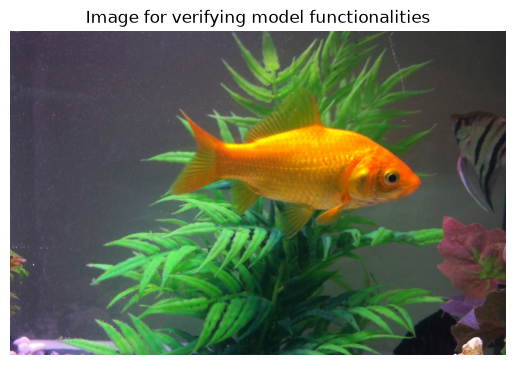

In [15]:
# Get sample image to test the models on to verify expected behavior
img_path = "../assets/WikipediaGoldfish.jpg"
img = Image.open(img_path).convert("RGB")

# Output image
plt.imshow(img)
plt.axis(False)
plt.title("Image for verifying model functionalities")
plt.show()

# Define transform for image
# Transforms are based on PyTorch's tutorial which also used IMAGENET1K_V1: 
# https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html
transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

goldfish_tensor = transform(img).unsqueeze(0).to(device) # (1, 3, 224, 224)

With the pre-processed image of the goldfish, we can now do a forward pass for each of the three models, and check whether the predicted class matches the expected class label of 1 (goldfish) for the ImageNet dataset.

In [16]:
# Verify that the pretrained models work as expected for inference
goldfish_label = 1 # Class label in the ImageNet dataset.

with torch.no_grad():
    for name, model in [("VGG-16", vgg_16), ("VGG-19", vgg_19), ("ResNet-152", resnet_152)]:
        output = model(goldfish_tensor) # shape (1, 1000)
        pred = torch.argmax(output).item() # Predicted label
        
        prob = torch.softmax(output, dim=1)[0].max().item() * 100 # softmax over columns to get probability distribution for each class. Convert to %. 
        print(f"{name} predicted the class index: {pred} ({prob:.2f}% certainty) " + ("\t[CORRECT]" if pred == goldfish_label else "\t[INCORRECT]"))

VGG-16 predicted the class index: 1 (100.00% certainty) 	[CORRECT]
VGG-19 predicted the class index: 1 (100.00% certainty) 	[CORRECT]
ResNet-152 predicted the class index: 1 (99.26% certainty) 	[CORRECT]


## 4. Implement reusable functions

- <p style="color:red">TODO: Implement reusable visualizations</p>
- <p style="color:red">TODO: Gradient ascent optimization loop (with support for optional regularization to support reusability for RQ2).</p>
- <p style="color:red">TODO: Helper for extracting model evaluation metrics of an input. e.g. top 5 accuracies relative to target class or similar.</p>

In [17]:
# Helper function which converts a tensor into an image and displays it
def tensor_to_image(image_tensor, plot=True, title=None):
    """Reverses ImageNet normalization of an image tensor and plots it

    Args:
        image_tensor (torch.Tensor): tensor with shape (num_channels, height, width) or (batch_size, num_channels, height, width)
        title (str): Title text for the image plot
    """
    
    # Ensure input is of shape (num_channels, height, width) from here on
    if image_tensor.dim() == 4:
        image_tensor = image_tensor.squeeze(0)

    # Undo ImageNet normalization
    mean = torch.tensor([0.485, 0.456, 0.406]).to(device).view(3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).to(device).view(3, 1, 1)
    img  = image_tensor * std + mean

    # Permute image dimensions from (num_channels, height, width) to (height, width, num_channels) to match matplotlib.imshow spec.
    img = img.permute(1, 2, 0).cpu().detach().numpy()

    if plot:
        plt.imshow(img)
        if title:
            plt.title(title)
        plt.axis(False)
        plt.show()

    return img

In [18]:
# Gradient ascent optimization helper for generating input image which maximizes target class
def gradient_ascent():
    """TODO
    """
    pass

In [19]:
# Evaluation helper which takes image tensor as input, and performs forward pass on a model and extracts quantitative metrics
def evaluate():
    """TODO
    """
    pass

## 5. RQ1 - Cross-model transferability

- <p style="color:red">TODO: Generate (via unregularized gradient ascent) feature visualizations which maximally activates a target class, using each model.</p>
- <p style="color:red">TODO: Evaluate how well visualizations transfer across the three models using both quantitative measures of transferability and subjective visual comparisons/analysis.</p>

## 6. RQ2 - Effect of optimization and regularization

- <p style="color:red">TODO: Compare unregularized gradient ascent against regularized variants (for the same set of starting images).</p>
- <p style="color:red">TODO: Evaluate changes in visual quality of output images via gradient ascent, and impact on cross-model transferability.</p>

## 7. Results, interpretation, and conclusions

- <p style="color:red">TODO: Write summary tables (perhaps a python lib can do this well? else markdown) of quantitative metrics.</p>
- <p style="color:red">TODO: Side by side comparisons before & after regularization would likely do well here.</p>
- <p style="color:red">TODO: Write final conclusions regarding the initial hypothesis for RQ1 and RQ2.</p>